# Validation and improvement of the OLS baseline (simple version)

Four questions, one short section each:

1. Is the data clean, with no leakage?
2. Is "tomorrow = today" a fair baseline?
3. Does the OLS still miss the weekly cycle?
4. Does one extra feature (`lag_6`) fix it?

Run in the same folder as `modelling_dataset.csv`.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import mean_absolute_error as mae, root_mean_squared_error as rmse, r2_score

TARGET = 'target_next_day'
BASE_FEATURES = ['avg_price', 'rolling_std_7', 'price_change_1d', 'price_change_7d', 'brent_price_usd', 'aud_per_usd']
SHOCK_START, POST_SHOCK_START = pd.Timestamp('2026-03-04'), pd.Timestamp('2026-06-21')

# Load and split exactly as the baseline notebook does
raw = pd.read_csv('modelling_dataset.csv', parse_dates=['date']).sort_values('date').set_index('date')
df = raw.dropna().copy()
df['lag_6'] = df['avg_price'].shift(6)   # price on the weekday we predict, one week earlier (past data only)
df = pd.get_dummies(df, columns=['day_of_week'], prefix='dow', drop_first=True, dtype=int)
FEATURES = BASE_FEATURES + [c for c in df.columns if c.startswith('dow_')]

n = len(df)
train, val, test = df.iloc[:int(n * 0.70)], df.iloc[int(n * 0.70):int(n * 0.85)], df.iloc[int(n * 0.85):]


def fit(frame, features):
    return sm.OLS(frame[TARGET], sm.add_constant(frame[features].astype(float))).fit()

def predict(model, frame, features):
    return model.predict(sm.add_constant(frame[features].astype(float)))

def dm_test(actual, pred_a, pred_b, max_lag=7):
    """Diebold-Mariano test on absolute errors. diff < 0 means model A is better; p < 0.05 means not luck."""
    d = np.abs(np.asarray(actual) - np.asarray(pred_a)) - np.abs(np.asarray(actual) - np.asarray(pred_b))
    var = d.var()
    for k in range(1, max_lag + 1):
        var += 2 * (1 - k / (max_lag + 1)) * np.mean((d[k:] - d.mean()) * (d[:-k] - d.mean()))
    z = d.mean() / np.sqrt(var / len(d))
    return d.mean(), 2 * (1 - norm.cdf(abs(z)))

baseline = fit(train, FEATURES)
pred_base = predict(baseline, test, FEATURES)

## 1. Data and leakage checks

In [2]:
checks = {
    'No missing days or duplicate dates': len(pd.date_range(raw.index.min(), raw.index.max()).difference(raw.index)) == 0
                                          and not raw.index.duplicated().any(),
    "target = tomorrow's avg_price":       np.allclose(raw[TARGET].iloc[:-1], raw['avg_price'].shift(-1).iloc[:-1]),
    'price_change_1d uses only past data': np.allclose(raw['price_change_1d'].iloc[1:], (raw['avg_price'] - raw['lag_1']).iloc[1:]),
    'train < validation < test in time':   train.index.max() < val.index.min() and val.index.max() < test.index.min(),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\nTest prices reach {test['avg_price'].max():.0f} c/L; the model only saw up to {train['avg_price'].max():.0f} c/L in training.")

PASS  No missing days or duplicate dates
PASS  target = tomorrow's avg_price
PASS  price_change_1d uses only past data
PASS  train < validation < test in time

Test prices reach 258 c/L; the model only saw up to 223 c/L in training.


## 2. Is the naive baseline fair?

Perth prices repeat weekly, so "tomorrow = today" is wrong on every Wednesday spike.
A fairer baseline is the **seasonal naive**: tomorrow = the price on the same weekday last week (`lag_6`).

In [3]:
models = {'Naive (tomorrow = today)': test['avg_price'],
          'Seasonal naive (same weekday last week)': test['lag_6'],
          'OLS baseline': pred_base}

print(f"{'Test set':42s} {'MAE':>6s} {'RMSE':>6s} {'R2':>6s}")
for name, pred in models.items():
    print(f"{name:42s} {mae(test[TARGET], pred):6.2f} {rmse(test[TARGET], pred):6.2f} {r2_score(test[TARGET], pred):6.3f}")

print("\nDiebold-Mariano test (is the OLS difference real?):")
for name, other in [('naive', test['avg_price']), ('seasonal naive', test['lag_6'])]:
    diff, p = dm_test(test[TARGET], pred_base, other)
    print(f"  OLS vs {name:15s}: MAE difference {diff:+.2f} c/L, p = {p:.4f}")

Test set                                      MAE   RMSE     R2
Naive (tomorrow = today)                     6.80  10.50  0.674
Seasonal naive (same weekday last week)      3.85   7.79  0.820
OLS baseline                                 6.62   8.08  0.807

Diebold-Mariano test (is the OLS difference real?):
  OLS vs naive          : MAE difference -0.18 c/L, p = 0.5924
  OLS vs seasonal naive : MAE difference +2.77 c/L, p = 0.0001


## 3. Does the OLS still miss the weekly cycle?

Durbin-Watson only checks lag 1. Because the series repeats every 7 days, we also check lag 7.
VIF above about 10 means a predictor is mostly explained by the others.

In [4]:
resid = baseline.resid
print(f"Durbin-Watson (lag 1)             : {durbin_watson(resid):.2f}")
print(f"Residual autocorrelation at lag 7 : {resid.autocorr(7):+.2f}   (large = weekly cycle left in the errors)")

X = train[FEATURES].astype(float)
print(f"Largest VIF in the baseline       : {max(variance_inflation_factor(X.values, i) for i in range(X.shape[1])):.1f}")

Durbin-Watson (lag 1)             : 2.09
Residual autocorrelation at lag 7 : +0.76   (large = weekly cycle left in the errors)
Largest VIF in the baseline       : 152.6


## 4. Improvement: add `lag_6`

Chosen on the **validation** set; the test set is used once.

In [5]:
train6 = train.dropna(subset=['lag_6'])        # drops only the first 6 training rows
FEATURES_NEW = FEATURES + ['lag_6']
improved = fit(train6, FEATURES_NEW)

print("Validation MAE:  baseline %.2f  ->  with lag_6 %.2f" % (
      mae(val[TARGET], predict(baseline, val, FEATURES)), mae(val[TARGET], predict(improved, val, FEATURES_NEW))))

pred_new = predict(improved, test, FEATURES_NEW)
print("\nTest set        :  baseline MAE %.2f RMSE %.2f R2 %.3f" % (mae(test[TARGET], pred_base), rmse(test[TARGET], pred_base), r2_score(test[TARGET], pred_base)))
print("                   with lag_6  MAE %.2f RMSE %.2f R2 %.3f" % (mae(test[TARGET], pred_new), rmse(test[TARGET], pred_new), r2_score(test[TARGET], pred_new)))

diff, p = dm_test(test[TARGET], pred_new, test['lag_6'])
print(f"\nDiebold-Mariano, with lag_6 vs seasonal naive: MAE difference {diff:+.2f} c/L, p = {p:.4f}")
print(f"Largest VIF with lag_6: {max(variance_inflation_factor(train6[FEATURES_NEW].astype(float).values, i) for i in range(len(FEATURES_NEW))):.1f}  (use it for prediction, not for reading coefficients)")

Validation MAE:  baseline 6.86  ->  with lag_6 1.44

Test set        :  baseline MAE 6.62 RMSE 8.08 R2 0.807
                   with lag_6  MAE 2.22 RMSE 3.33 R2 0.967

Diebold-Mariano, with lag_6 vs seasonal naive: MAE difference -1.63 c/L, p = 0.0068
Largest VIF with lag_6: 645.2  (use it for prediction, not for reading coefficients)


In [6]:
ev = pd.DataFrame({'date': test.index, 'actual': test[TARGET].values, 'baseline': pred_base.values,
                   'with_lag_6': pred_new.values, 'naive': test['avg_price'].values, 'seasonal_naive': test['lag_6'].values})
ev['regime'] = np.where(ev['date'] >= POST_SHOCK_START, 'post_shock', np.where(ev['date'] >= SHOCK_START, 'shock', 'normal'))

table = ev.groupby('regime').apply(lambda s: pd.Series({
    'days': len(s), 'OLS baseline': mae(s.actual, s.baseline), 'OLS + lag_6': mae(s.actual, s.with_lag_6),
    'Naive': mae(s.actual, s.naive), 'Seasonal naive': mae(s.actual, s.seasonal_naive)}), include_groups=False)
print("MAE by regime (c/L):")
print(table.loc[['normal', 'shock', 'post_shock']].round(2).to_string())

MAE by regime (c/L):
             days  OLS baseline  OLS + lag_6  Naive  Seasonal naive
regime                                                             
normal      425.0          6.74         1.88   7.70            1.58
shock       109.0          6.36         3.65   3.51           12.50
post_shock   10.0          4.32         1.41   4.23            6.28


### Figure 5: baseline vs improved model

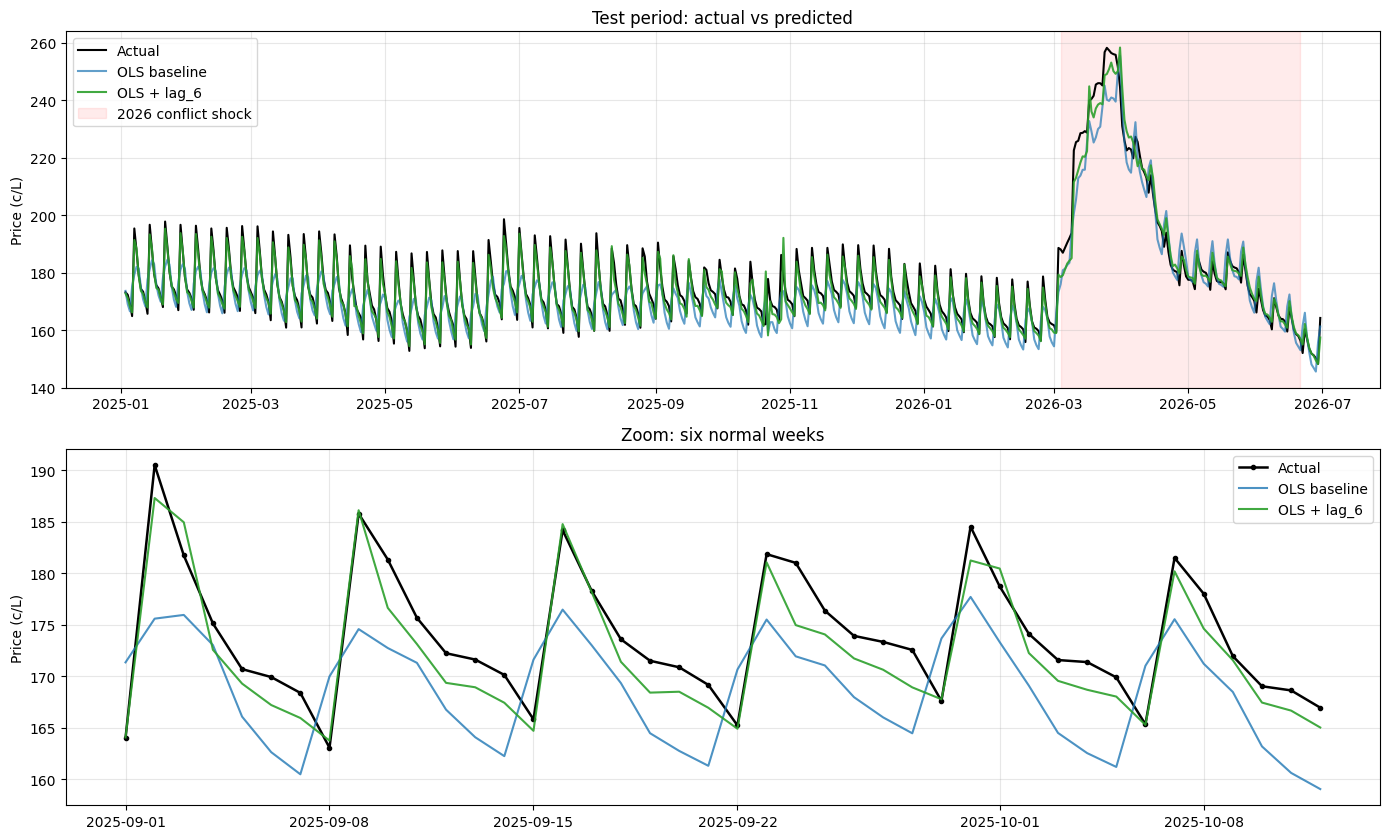

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8.5))

axes[0].plot(ev['date'], ev['actual'], color='black', lw=1.5, label='Actual')
axes[0].plot(ev['date'], ev['baseline'], color='tab:blue', alpha=0.7, label='OLS baseline')
axes[0].plot(ev['date'], ev['with_lag_6'], color='tab:green', alpha=0.9, label='OLS + lag_6')
axes[0].axvspan(SHOCK_START, POST_SHOCK_START, color='red', alpha=0.08, label='2026 conflict shock')
axes[0].set_title('Test period: actual vs predicted'); axes[0].legend(loc='upper left')

zoom = ev[(ev['date'] >= '2025-09-01') & (ev['date'] < '2025-10-13')]
axes[1].plot(zoom['date'], zoom['actual'], color='black', lw=1.8, marker='o', ms=3, label='Actual')
axes[1].plot(zoom['date'], zoom['baseline'], color='tab:blue', alpha=0.8, label='OLS baseline')
axes[1].plot(zoom['date'], zoom['with_lag_6'], color='tab:green', alpha=0.9, label='OLS + lag_6')
axes[1].set_title('Zoom: six normal weeks'); axes[1].legend(loc='upper right')

for ax in axes:
    ax.set_ylabel('Price (c/L)'); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('fig5_improved_vs_baseline.png', dpi=150); plt.show()